# code_084 · Kernels and implicit feature spaces

**Book:** section 17.3. A self-contained similarity-and-margin laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_17_GUIDE.md), [run evidence](../CHAPTER_17_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_084).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1784;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1784


<a id="kernels"></a>
## A kernel is a specified geometry, not an arbitrary similarity score

Generate source train120/development80/final200 with load in[-1,1] and seasonal time0–12 months. Response=.8*load+sin(2*pi*time/12)+Normal(.15). A sixty-record future cohort uses months12–24. The period12 is declared by construction, not inferred from assessment. Training-only load mean/SD and a fixed training-response mean offset are retained. Compare linear, RBF(gamma1) and additive linear-load plus periodic(length.7,period12) kernels. A common kernel-ridge solve(K+n*lambda*I) uses lambda.001/.01/.1/1 selected by development MSE. These are response fits, not probability outputs. An independent frozen load-zero slice across two cycles supplies plotted predictions and noisy observations, with no assessment-driven tuning.


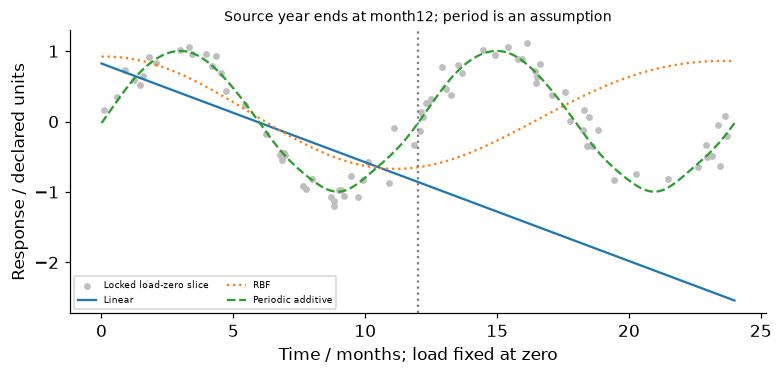

In [2]:
from sklearn.metrics import mean_squared_error
from scipy.spatial.distance import cdist
def generate(n,low=0,high=12):
 a=np.column_stack([rng.uniform(-1,1,n),rng.uniform(low,high,n)]);return a,.8*a[:,0]+np.sin(2*np.pi*a[:,1]/12)+rng.normal(0,.15,n)
X,y=generate(120);Xd,yd=generate(80);Xt,yt=generate(200);Xf,yf=generate(60,12,24);load_mean=X[:,0].mean();load_sd=X[:,0].std();time_mean=X[:,1].mean();offset=float(y.mean())
def transformed(a):return np.column_stack([(a[:,0]-load_mean)/load_sd,(a[:,1]-time_mean)/12])
def kernel(a,b,name):
 u=transformed(a);v=transformed(b)
 if name=='Linear':return u@v.T
 if name=='RBF':return np.exp(-cdist(u,v,'sqeuclidean'))
 return np.outer(u[:,0],v[:,0])+np.exp(-2*np.sin(np.pi*(a[:,1,None]-b[None,:,1])/12)**2/.7**2)
names=['Linear','RBF','Periodic additive'];lambdas=[.001,.01,.1,1];fits={};rows=[]
for name in names:
 K=kernel(X,X,name);assert np.linalg.eigvalsh(K).min()>-1e-9;options=[]
 for lam in lambdas:
  coef=np.linalg.solve(K+len(y)*lam*np.eye(len(y)),y-offset);options.append((float(mean_squared_error(yd,offset+kernel(Xd,X,name)@coef)),lam,coef))
 dev,lam,coef=min(options,key=lambda r:r[0]);fits[name]=coef;rows.append({'kernel':name,'lambda':lam,'development_mse':dev,'source_final_mse':float(mean_squared_error(yt,offset+kernel(Xt,X,name)@coef)),'future_mse':float(mean_squared_error(yf,offset+kernel(Xf,X,name)@coef))})
RESULTS['kernel_fits']=rows;RESULTS['roles']={'source_train':120,'development':80,'source_final':200,'future_final':60,'known_period_months':12,'fixed_training_mean_offset':offset}
grid=np.column_stack([np.zeros(200),np.linspace(0,24,200)]);slice_X=np.column_stack([np.zeros(80),rng.uniform(0,24,80)]);slice_y=np.sin(2*np.pi*slice_X[:,1]/12)+rng.normal(0,.15,80);fig,ax=plt.subplots(figsize=(7,3.3));ax.scatter(slice_X[:,1],slice_y,s=12,color='.75',label='Locked load-zero slice')
for name,style in zip(names,['-',':','--']):ax.plot(grid[:,1],offset+kernel(grid,X,name)@fits[name],style,label=name)
ax.axvline(12,color='.5',ls=':');ax.set(xlabel='Time / months; load fixed at zero',ylabel='Response / declared units',title='Source year ends at month12; period is an assumption');ax.legend(fontsize=6,ncol=2);plt.show()


<a id="features"></a>
## Check a finite feature map and reject an indefinite matrix

For two inputs, phi(x)=[1,sqrt2*x1,sqrt2*x2,x1²,sqrt2*x1*x2,x2²] gives phi(x).phi(z)=(1+x.z)^2 exactly up to arithmetic tolerance. This explicit polynomial identity illustrates a kernel geometry; it is not the RBF's finite feature map. A symmetric similarity matrix[[1,2],[2,1]] has eigenvalue-1, so it cannot be an ordinary real inner-product Gram matrix. Symmetry alone is insufficient. Kernel choice controls smoothness, locality and periodic repetition, and source-year success alone does not establish future behavior under an untested period.


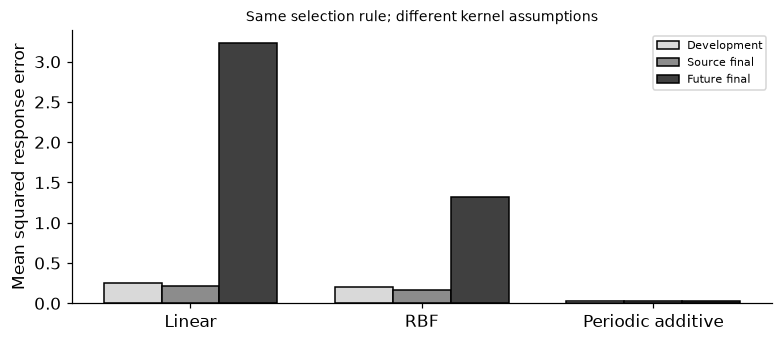

In [3]:
u=transformed(X[:12]);phi=np.column_stack([np.ones(len(u)),np.sqrt(2)*u[:,0],np.sqrt(2)*u[:,1],u[:,0]**2,np.sqrt(2)*u[:,0]*u[:,1],u[:,1]**2]);np.testing.assert_allclose(phi@phi.T,(1+u@u.T)**2,atol=1e-12);assert np.linalg.eigvalsh(phi@phi.T).min()>-1e-9;bad=np.array([[1.,2.],[2.,1.]]);assert np.linalg.eigvalsh(bad).min()<0
RESULTS['feature_geometry']={'polynomial_feature_dimensions':6,'polynomial_identity_passed':True,'indefinite_similarity_eigenvalues':np.linalg.eigvalsh(bad).tolist(),'RBF_finite_map_claimed':False};RESULTS['locked_slice']={'rows':80,'kernel_mse':{name:float(mean_squared_error(slice_y,offset+kernel(slice_X,X,name)@fits[name])) for name in names}}
fig,ax=plt.subplots(figsize=(7,3));positions=np.arange(3)
for j,key in enumerate(['development_mse','source_final_mse','future_mse']):ax.bar(positions+(j-1)*.25,[r[key] for r in rows],width=.25,color=['.85','.55','.25'][j],edgecolor='black',label=['Development','Source final','Future final'][j])
ax.set(xticks=positions,xticklabels=names,ylabel='Mean squared response error',title='Same selection rule; different kernel assumptions');ax.legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_084','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['positive-semidefinite Gram matrices', 'explicit polynomial feature identity', 'common-objective kernel ridge', 'linear radial and periodic assumptions'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["positive-semidefinite Gram matrices", "explicit polynomial feature identity", "common-objective kernel ridge", "linear radial and periodic assumptions"], "elapsed_seconds": 0.198, "example_id": "code_084", "hardware": "Darwin arm64 CPU", "results": {"feature_geometry": {"RBF_finite_map_claimed": false, "indefinite_similarity_eigenvalues": [-1.0, 3.0], "polynomial_feature_dimensions": 6, "polynomial_identity_passed": true}, "kernel_fits": [{"development_mse": 0.2544115490319677, "future_mse": 3.2279586872258172, "kernel": "Linear", "lambda": 0.01, "source_final_mse": 0.21542351656424344}, {"development_mse": 0.19945319632763142, "future_mse": 1.324874896471943, "kernel": "RBF", "lambda": 0.001, "source_final_mse": 0.16833236201694746}, {"development_mse": 0.022391579068339818, "future_mse": 0.02408029200875308, "kernel": "Periodic additive", "lambda": 0.001, "source_final_mse": 0.02222641182906238}], "locked_slice": {"kernel_mse": {"Lin